## Simple MultiAI Agent Architecture

In [1]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

C:\Users\Admin\AppData\Local\Temp\ipykernel_24772\924501044.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [3]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [13]:
## Define the state

##MessagesState - MessagesState is a prebuilt state schema in LangGraph that gives your graph a single built-in key, messages, which holds the conversation as a list of message objects (HumanMessage, AIMessage, ToolMessage, etc.).
class AgentState(MessagesState):
    ## important note - message : Annotated[[list], add_messages] ...this is already present in MessageStates

    ## include extra variable next_agent
    next_agent:str #which agent should go next 

In [14]:
# Create simple tools
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearchResults(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    summary = f"Summary of findings:\n\n{content[:500]}..."
    return summary

In [15]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(model="openai/gpt-oss-20b", model_provider="groq")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002306A25DBD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002306A25E5D0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [16]:
# Define agent functions (simpler approach)
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    
    messages = state["messages"]
    
    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find information about the user's request.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)
    
    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [17]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""
    
    messages = state["messages"]
    
    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")
    
    # Simple completion without tools
    writer_llm = llm.bind_tools([write_summary])
    response = writer_llm.invoke([system_msg] + messages)
    
    return {
        "messages": [response],
        "next_agent": "end"
    }

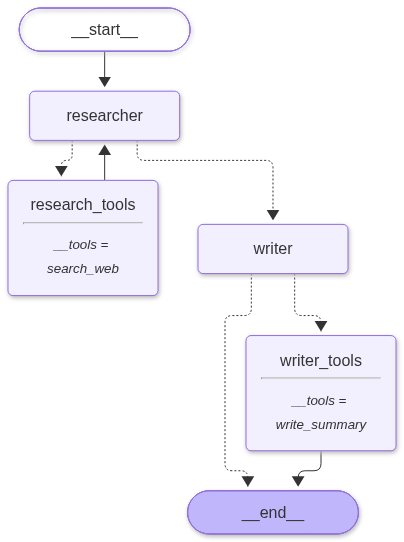

In [18]:
research_tools = ToolNode([search_web])       # researcher's tools only
writer_tools = ToolNode([write_summary])      # writer's tools only

def route_after_researcher(state: AgentState):
    return "research_tools" if state["messages"][-1].tool_calls else "writer"

def route_after_writer(state: AgentState):
    return "writer_tools" if state["messages"][-1].tool_calls else END

workflow = StateGraph(AgentState)

workflow.add_node("researcher", researcher_agent)
workflow.add_node("research_tools", research_tools)
workflow.add_node("writer", writer_agent)
workflow.add_node("writer_tools", writer_tools)

workflow.set_entry_point("researcher")

workflow.add_conditional_edges(
    "researcher", route_after_researcher,
    {"research_tools": "research_tools", "writer": "writer"},
)
workflow.add_edge("research_tools", "researcher")   # search results go back to researcher

workflow.add_conditional_edges(
    "writer", route_after_writer,
    {"writer_tools": "writer_tools", END: END},
)
workflow.add_edge("writer_tools", END)              # tool output is the final answer

final_workflow = workflow.compile()
final_workflow

In [19]:
response=final_workflow.invoke({"messages":"Reasearch about the usecase of agentic ai in business"})

C:\Users\Admin\AppData\Local\Temp\ipykernel_29352\3356794159.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search = TavilySearchResults(max_results=3)


In [23]:
response

{'messages': [HumanMessage(content='Reasearch about the usecase of agentic ai in business', additional_kwargs={}, response_metadata={}, id='84715df9-9e03-45b1-be74-0faf7516d5d9'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "Reasearch about the usecase of agentic ai in business". They likely want an overview of use cases of agentic AI (i.e., AI systems that can act autonomously, make decisions, etc.) in business. We need to research this. We should use the search_web tool. We\'ll search for "agentic AI use cases in business" or similar. Let\'s do that.', 'tool_calls': [{'id': 'fc_f2cc51a9-250c-405a-993b-8d573c8fb395', 'function': {'arguments': '{"query":"agentic AI use cases in business"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 154, 'total_tokens': 268, 'completion_time': 0.127757613, 'completion_tokens_details': {'reasoning_tokens': 85}, 'prompt_time': 0.007734124,

In [21]:
response["messages"][-1].content

'Summary of findings:\n\n**Agentic AI in Business – Key Findings (2024‑2026)**\n\n1. **What is Agentic AI?**\n   - AI systems that can reason through multi‑step workflows, interact with external APIs or systems, and execute actions autonomously while retaining human oversight.\n\n2. **Primary Business Functions Leveraging Agentic AI**\n   - **Customer Service & Support** – 24/7 chatbots, proactive diagnostics, and automated ticket resolution.  Example: Walmart’s LLM‑powered personal shopping assistant and Klarna’s AI chat han...'

## supervise Multi Ai Agent Architecture

In [4]:
from typing import TypedDict, Annotated, List, Literal, Dict, Any
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
import random
from datetime import datetime
from langchain.chat_models import init_chat_model

In [5]:
llm = init_chat_model(model = "openai/gpt-oss-20b", model_provider = "groq")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000012772988590>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000012772988EC0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
response = llm.invoke("hello")
response

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 72, 'total_tokens': 97, 'completion_time': 0.025611827, 'completion_tokens_details': {'reasoning_tokens': 7}, 'prompt_time': 0.003819815, 'prompt_tokens_details': None, 'queue_time': 0.365389111, 'total_time': 0.029431642}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8b41efc9a3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a2111f-2bc1-70ff-adfe-1c2517f4ed8c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 25, 'total_tokens': 97, 'output_token_details': {'reasoning': 7}})

In [7]:
## define State

class SupervisorState(MessagesState):
    """State for the multi-agent system"""
    next_agent: str = ""
    research_data: str = ""
    analysis: str = ""
    final_report: str = ""
    task_complete: bool = False
    current_task: str = ""

In [8]:
## Supervisor chain
from langchain_core.prompts import ChatPromptTemplate
def create_supervisor_chain():
    """Creates the supervisor decision chain"""
    
    supervisor_prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a supervisor managing a team of agents:
        
1. Researcher - Gathers information and data
2. Analyst - Analyzes data and provides insights  
3. Writer - Creates reports and summaries

Based on the current state and conversation, decide which agent should work next.
If the task is complete, respond with 'DONE'.

Current state:
- Has research data: {has_research}
- Has analysis: {has_analysis}
- Has report: {has_report}

Respond with ONLY the agent name (researcher/analyst/writer) or 'DONE'.
"""),
        ("human", "{task}") ## task is our question
    ]) 
    
    return supervisor_prompt | llm ## chaining llma nd supervisor_prompt

In [9]:
## define Supervisor agent

def supervisor_agent(state: SupervisorState) -> Dict:
    """Supervisor decides next agent using Groq LLM"""
    
    messages = state["messages"]
    task = messages[-1].content if messages else "No task" ## task is our question
    
    # Check what's been completed
    has_research = bool(state.get("research_data", ""))
    has_analysis = bool(state.get("analysis", ""))
    has_report = bool(state.get("final_report", ""))
    
    # Get LLM decision
    chain = create_supervisor_chain()
    decision = chain.invoke({
        "task": task,
        "has_research": has_research,
        "has_analysis": has_analysis,
        "has_report": has_report
    })
    
    # Parse decision
    decision_text = decision.content.strip().lower()
    print(decision_text)
    
    # Determine next agent
    if "done" in decision_text or has_report:
        next_agent = "end"
        supervisor_msg = "✅ Supervisor: All tasks complete! Great work team."
    elif "researcher" in decision_text or not has_research:
        next_agent = "researcher"
        supervisor_msg = "📋 Supervisor: Let's start with research. Assigning to Researcher..."
    elif "analyst" in decision_text or (has_research and not has_analysis):
        next_agent = "analyst"
        supervisor_msg = "📋 Supervisor: Research done. Time for analysis. Assigning to Analyst..."
    elif "writer" in decision_text or (has_analysis and not has_report):
        next_agent = "writer"
        supervisor_msg = "📋 Supervisor: Analysis complete. Let's create the report. Assigning to Writer..."
    else:
        next_agent = "end"
        supervisor_msg = "✅ Supervisor: Task seems complete."
    
    return {
        "messages": [AIMessage(content=supervisor_msg)],
        "next_agent": next_agent,
        "current_task": task ## task is our question
    }

In [15]:
## agent 1 - researcher
def researcher_agent(state: SupervisorState) -> Dict:
    """Researcher uses Groq to gather information"""
    
    task = state.get("current_task", "research topic") ## task is our question
    
    # Create research prompt
    research_prompt = f"""As a research specialist, provide comprehensive information about: {task}

    Include:
    1. Key facts and background
    2. Current trends or developments
    3. Important statistics or data points
    4. Notable examples or case studies
    
    Be concise but thorough."""
    
    # Get research from LLM
    research_response = llm.invoke([HumanMessage(content=research_prompt)])
    research_data = research_response.content
    
    # Create agent message
    agent_message = f"🔍 Researcher: I've completed the research on '{task}'.\n\nKey findings:\n{research_data[:500]}..."
    
    return {
        "messages": [AIMessage(content=agent_message)],
        "research_data": research_data,
        "next_agent": "supervisor" 
    }

In [10]:

# agent 2: Analyst 

def analyst_agent(state: SupervisorState) -> Dict:
    """Analyst uses Groq to analyze the research"""
    
    research_data = state.get("research_data", "")
    task = state.get("current_task", "")
    
    # Create analysis prompt
    analysis_prompt = f"""As a data analyst, analyze this research data and provide insights:

Research Data:
{research_data}

Provide:
1. Key insights and patterns
2. Strategic implications
3. Risks and opportunities
4. Recommendations

Focus on actionable insights related to: {task}"""
    
    # Get analysis from LLM
    analysis_response = llm.invoke([HumanMessage(content=analysis_prompt)])
    analysis = analysis_response.content
    
    # Create agent message
    agent_message = f"📊 Analyst: I've completed the analysis.\n\nTop insights:\n{analysis[:400]}..."
    
    return {
        "messages": [AIMessage(content=agent_message)],
        "analysis": analysis,
        "next_agent": "supervisor"
    }

In [11]:

# Agent 3: Writer 

def writer_agent(state: SupervisorState) -> Dict:
    """Writer uses Groq to create final report"""
    
    research_data = state.get("research_data", "")
    analysis = state.get("analysis", "")
    task = state.get("current_task", "")
    
    # Create writing prompt
    writing_prompt = f"""As a professional writer, create an executive report based on:

Task: {task}

Research Findings:
{research_data[:1000]}

Analysis:
{analysis[:1000]}

Create a well-structured report with:
1. Executive Summary
2. Key Findings  
3. Analysis & Insights
4. Recommendations
5. Conclusion

Keep it professional and concise."""
    
    # Get report from LLM
    report_response = llm.invoke([HumanMessage(content=writing_prompt)])
    report = report_response.content
    
    # Create final formatted report
    final_report = f"""
📄 FINAL REPORT
{'='*50}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
Topic: {task}
{'='*50}

{report}

{'='*50}
Report compiled by Multi-Agent AI System powered by Groq
"""
    
    return {
        "messages": [AIMessage(content=f"✍️ Writer: Report complete! See below for the full document.")],
        "final_report": final_report,
        "next_agent": "supervisor",
        "task_complete": True
    }

In [12]:

# Router Function
## Literal is a type hint that says "this function can only return one of these exact values."
def router(state: SupervisorState) -> Literal["supervisor", "researcher", "analyst", "writer", "__end__"]:
    """Routes to next agent based on state"""
    
    next_agent = state.get("next_agent", "supervisor")
    
    if next_agent == "end" or state.get("task_complete", False):
        return END
        
    if next_agent in ["supervisor", "researcher", "analyst", "writer"]:
        return next_agent
        
    return "supervisor"

In [16]:
# Create workflow
workflow = StateGraph(SupervisorState)

# Add nodes
workflow.add_node("supervisor", supervisor_agent)
workflow.add_node("researcher", researcher_agent)
workflow.add_node("analyst", analyst_agent)
workflow.add_node("writer", writer_agent)

# Set entry point
workflow.set_entry_point("supervisor")

# Add routing
for node in ["supervisor", "researcher", "analyst", "writer"]:
    workflow.add_conditional_edges(
        node,
        router,
        {
            "supervisor": "supervisor",
            "researcher": "researcher",
            "analyst": "analyst",
            "writer": "writer",
            END: END
        }
    )

graph=workflow.compile()

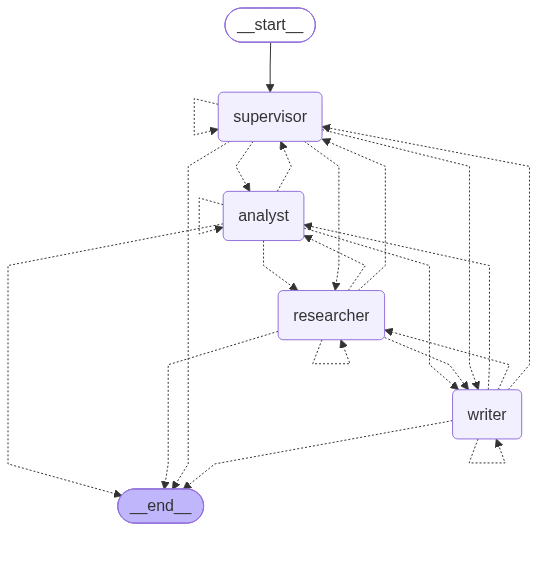

In [17]:
graph

In [18]:
response=graph.invoke(HumanMessage(content="What are the benefits and risks of AI in healthcare?"))


researcher
analyst
writer


In [19]:
response['final_report']

"\n📄 FINAL REPORT\n==================================================\nGenerated: 2026-11-25 10:43\nTopic: 📊 Analyst: I've completed the analysis.\n\nTop insights:\n## Executive Summary  \n*No task*—the moment when an individual, team, or system has nothing on its active queue—is no longer just a productivity “gap.”  Across the industry it has become a **strategic pause** that can either erode value or unlock creativity, depending on how it is managed.  The research shows:\n\n| Dimension | Current Reality | Why It Matters | Key Metric |\n|-----------|------------...\n==================================================\n\n**Executive Report – “No‑Task” as a Strategic Asset**  \n*Prepared for: Executive Leadership Team*  \n*Date: 25\u202fNov\u202f2026*  \n\n---\n\n### 1. Executive Summary  \nThe traditional view of “no‑task” – an idle period when an individual, team, or system has nothing on its active queue – is shifting from a productivity gap to a **strategic pause**. When deliberately